# Probability

## Challenge 1
There is a box with 10 white balls, 12 red balls and 8 black balls. Calculate the probability of:
* Taking a white ball out.
* Taking a white ball on first extraction and a black ball out on second extraction without replacing the first one.
* Taking a white ball on first extraction and a black ball out on second extraction replacing the first one.
* Taking 3 balls and them being all different colours.

In [ ]:
# YOUR CODE HERE

# Given data
white = 10      # number of white balls
red = 12        # number of red balls
black = 8       # number of black balls
total = white + red + black  # total number of balls = 30

# Probability of taking a white ball
p_white = white / total
print(f"1. Probability of taking a white ball: {p_white:.4f}")

# Probability of taking a white ball first and a black ball second WITHOUT replacement
# After taking one ball, there are 29 left
p_white_black_no_replace = (white / total) * (black / (total - 1))
print(f"2. White then black (no replacement): {p_white_black_no_replace:.4f}")

# Probability of taking a white ball first and a black ball second WITH replacement
# After first draw, the total number of balls stays the same (30)
p_white_black_replace = (white / total) * (black / total)
print(f"3. White then black (with replacement): {p_white_black_replace:.4f}")

# Probability of taking 3 balls of all different colors (no replacement)
# Formula = (white/total) * (red/(total-1)) * (black/(total-2)) * number_of_permutations
# There are 3! = 6 possible orders (W-R-B, W-B-R, R-W-B, R-B-W, B-W-R, B-R-W)
from math import comb  # comb(n, k) gives number of combinations n choose k

favorable = white * red * black   # choose 1 ball of each color
total_ways = comb(total, 3)       # all ways to pick 3 balls from 30
p_all_different = favorable / total_ways
print(f"4. Three balls all different colors: {p_all_different:.4f}")


1. Probability of taking a white ball: 0.3333
2. White then black (no replacement): 0.0920
3. White then black (with replacement): 0.0889
4. Three balls all different colors: 0.2365


## Challenge 2

You want to go on picnic on Saturday. You hate rain, and would know to plan your weekend. To help you make a decision, you gather the following data about rainy days:

* 40% of all days are cloudy.
* About 50% of cloudy days are rainy. 
* About 20% of non-cloudy days are rainy.

What is the chance of rain during next Saturday?

In [3]:
# YOUR CODE HERE 

# Given probabilities
p_cloudy = 0.4                  # 40% of all days are cloudy
p_not_cloudy = 1 - p_cloudy     # complement: 60% are not cloudy
p_rain_given_cloudy = 0.5       # 50% of cloudy days are rainy
p_rain_given_not_cloudy = 0.2   # 20% of non-cloudy days are rainy

# Law of Total Probability:
# P(Rain) = P(Rain|Cloudy)*P(Cloudy) + P(Rain|NotCloudy)*P(NotCloudy)
p_rain = (p_rain_given_cloudy * p_cloudy) + (p_rain_given_not_cloudy * p_not_cloudy)

# Print results
print(f"Probability of rain on Saturday: {p_rain:.2%}")   # percentage format
print(f"As decimal: {p_rain:.4f}")


Probability of rain on Saturday: 32.00%
As decimal: 0.3200


## Challenge 3

A and B are events of a probability such that $P(A) = 0.3$, $P(B) = 0.6$ and $P(A \cap B) = 0.1$

Which of the following statements are true?  
**HINT: draw a big Venn Diagram by your side**  
* $P(\overline{A}) = 0.7$
* $P(A \cup B) = 0.6$
* $P(A \cap \overline{B}) = 0.2$
* $P(A \cup \overline{A}) = 1$  
* $P(A \cap (B \cup \overline{B})) = 0.4$
* $P(\overline{A} \cap \overline{B}) = 0.3$
* $P(\overline{A \cap B}) = 0.9$

In [ ]:
# YOUR CODE HERE

# Given probabilities
p_A = 0.3
p_B = 0.6
p_A_and_B = 0.1

# Complements
p_not_A = 1 - p_A
p_not_B = 1 - p_B

# P(A̅)
P1 = p_not_A

# P(A ∪ B) = P(A) + P(B) - P(A ∩ B)
P2 = p_A + p_B - p_A_and_B

# P(A ∩ B̅) = P(A) - P(A ∩ B)
P3 = p_A - p_A_and_B

# P(A ∪ A̅) = 1 (always)
P4 = 1

# P(A ∩ (B ∪ B̅)) = P(A) since (B ∪ B̅) = Ω (the whole sample space)
P5 = p_A

# P(A̅ ∩ B̅) = 1 - P(A ∪ B)
P6 = 1 - P2

# P((A ∩ B)̅) = 1 - P(A ∩ B)
P7 = 1 - p_A_and_B

# Store expected answers from question text to check truth values
expected_values = {
    "P(A̅)": 0.7,
    "P(A ∪ B)": 0.6,
    "P(A ∩ B̅)": 0.2,
    "P(A ∪ A̅)": 1,
    "P(A ∩ (B ∪ B̅))": 0.4,
    "P(A̅ ∩ B̅)": 0.3,
    "P((A ∩ B)̅)": 0.9
}

# Store computed values
computed_values = [P1, P2, P3, P4, P5, P6, P7]
labels = list(expected_values.keys())

# Print results nicely
for label, computed in zip(labels, computed_values):
    expected = expected_values[label]
    truth = "✅ True" if abs(computed - expected) < 1e-6 else "❌ False"
    print(f"{label}: computed={computed:.2f}, expected={expected:.2f} → {truth}")


P(A̅): computed=0.70, expected=0.70 → ✅ True
P(A ∪ B): computed=0.80, expected=0.60 → ❌ False
P(A ∩ B̅): computed=0.20, expected=0.20 → ✅ True
P(A ∪ A̅): computed=1.00, expected=1.00 → ✅ True
P(A ∩ (B ∪ B̅)): computed=0.30, expected=0.40 → ❌ False
P(A̅ ∩ B̅): computed=0.20, expected=0.30 → ❌ False
P((A ∩ B)̅): computed=0.90, expected=0.90 → ✅ True


## Challenge 4

 * If someone flies to China, the probability of getting Covid is 1%  
 * If someone flies to Italy, the probability of getting Covid is 20%  

I roll 1 dice with numbers 1, 2, 3, 4, 5, 6:  
 * If 1: I fly to Italy
 * If not 1: I fly to China

During my trip, I got Covid. What is the probability that I flew to China?

In [ ]:
# YOUR CODE HERE

# Probabilities
p_italy = 1/6
p_china = 5/6
p_covid_given_italy = 0.20
p_covid_given_china = 0.01

# Total probability of Covid (law of total probability)
p_covid = (p_covid_given_italy * p_italy) + (p_covid_given_china * p_china)

# Bayes theorem: P(China | Covid)
p_china_given_covid = (p_covid_given_china * p_china) / p_covid

# Print results
print(f"Total probability of Covid: {p_covid:.4f}")
print(f"Probability you went to China given you got Covid: {p_china_given_covid:.2%}")



Total probability of Covid: 0.0417
Probability you went to China given you got Covid: 20.00%


## BONUS

You roll 2 dice. What is the probability that the sum of the numbers is 7? And 8? And 9? Then simulate 10000 times and draw a countplot.

your explanation here

Theoretical probabilities:
P(sum = 7) = 0.1667  (16.67%)
P(sum = 8) = 0.1389  (13.89%)
P(sum = 9) = 0.1111  (11.11%)

Simulated probabilities (N = 10,000):
P̂(sum = 7) = 0.1616  (16.16%), count = 1616
P̂(sum = 8) = 0.1414  (14.14%), count = 1414
P̂(sum = 9) = 0.1105  (11.05%), count = 1105


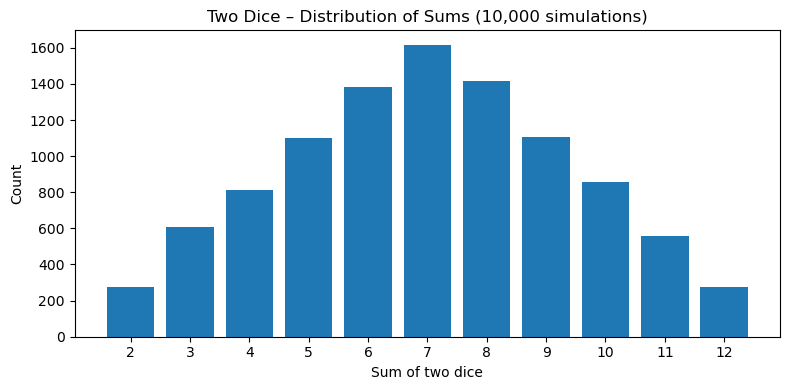

In [10]:
# YOUR CODE HERE

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Theoretical probabilities 
def theoretical_prob(sum_val):
    """Return theoretical probability for a given sum of two dice (2–12)."""
    if 2 <= sum_val <= 12:
        count = 6 - abs(7 - sum_val)   # pattern: 1,2,3,4,5,6,5,4,3,2,1
        return count / 36
    return 0.0

sums_of_interest = [7, 8, 9]

print("Theoretical probabilities:")
for s in sums_of_interest:
    p = theoretical_prob(s)
    print(f"P(sum = {s}) = {p:.4f}  ({p*100:.2f}%)")

# Simulation 
np.random.seed(42)      # reproducibility
N = 10_000              # number of experiments
die1 = np.random.randint(1, 7, N)
die2 = np.random.randint(1, 7, N)
sums = die1 + die2

# Count how many times each sum appeared
counts = Counter(sums)

print("\nSimulated probabilities (N = 10,000):")
for s in sums_of_interest:
    p_sim = counts[s] / N
    print(f"P̂(sum = {s}) = {p_sim:.4f}  ({p_sim*100:.2f}%), count = {counts[s]}")

# Plot countplot (bar chart) 
x_vals = list(range(2, 13))  # possible sums 2..12
y_counts = [counts.get(x, 0) for x in x_vals]

plt.figure(figsize=(8,4))
plt.bar(x_vals, y_counts)
plt.title("Two Dice – Distribution of Sums (10,000 simulations)")
plt.xlabel("Sum of two dice")
plt.ylabel("Count")
plt.xticks(x_vals)
plt.tight_layout()
plt.show()
